In [1]:
import re
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [2]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses).xlsx to Blank Quiz (Responses).xlsx
File terbaca: Blank Quiz (Responses).xlsx


In [3]:
JUMLAH_KOLOM_DEMOGRAFI = 6

df = pd.read_excel(nama_file)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 39
Jumlah butir     : 29
Data kosong      : 0


In [4]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


/tmp/ipykernel_749/2502456638.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,3,4,5,3,4,5,5,4,3,3,...,2,3,3,3,3,4,4,5,4,5
1,4,5,4,4,2,5,4,3,4,2,...,3,4,2,3,4,1,2,3,4,5
2,4,4,4,4,2,4,5,4,3,2,...,1,4,5,4,5,4,3,4,5,5
3,5,4,2,1,1,5,5,1,2,3,...,1,5,4,4,5,5,1,5,3,1
4,4,4,5,3,4,5,4,5,4,3,...,2,1,1,1,1,4,4,5,1,5


In [5]:
dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?) \[", kolom).group(1).strip()
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik.: 4 butir
Rsspon emosional: 5 butir


In [6]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 39 | r tabel (α=0,05; df=37) = 0.316


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.525,0.277,0.0006,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.269,0.105,0.0972,Tidak valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.643,0.379,0.0000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.669,0.397,0.0000,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.515,0.126,0.0008,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.455,0.139,0.0036,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.016,-0.247,0.9237,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.538,0.228,0.0004,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.645,0.377,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.495,0.213,0.0014,Valid


In [7]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.370,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.375,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.478,Tidak reliabel
3,Prokrastinasi akademik.,4,0.863,Baik
4,Rsspon emosional,5,0.489,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.275
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.362
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.193
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.171
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.367
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.348
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.513
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.299
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.200
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.312


,Dimensi / Butir,Mean,Median,Std Dev (SD),Skewness,Kurtosis
0,[TOTAL DIMENSI] Penggunaan AI pada tugas atau ...,27.282,27.0,3.017,-0.425,1.612
1,Penggunaan AI pada tugas atau projek kuliah ...,4.026,4.0,0.843,-0.606,-0.057
2,Penggunaan AI pada tugas atau projek kuliah ...,4.487,4.0,0.506,0.053,-2.108
3,Penggunaan AI pada tugas atau projek kuliah ...,4.256,4.0,0.993,-1.743,2.975
4,Penggunaan AI pada tugas atau projek kuliah ...,2.949,3.0,1.050,-0.037,-0.691
5,Penggunaan AI pada tugas atau projek kuliah ...,2.974,3.0,1.224,-0.130,-1.170
6,Penggunaan AI pada tugas atau projek kuliah ...,4.179,4.0,0.997,-1.388,1.847
7,Penggunaan AI pada tugas atau projek kuliah ...,4.410,5.0,0.818,-1.519,2.143
8,[TOTAL DIMENSI] Aspek Psikologis penggunaan AI...,21.923,21.0,3.737,0.248,-0.752
9,Aspek Psikologis penggunaan AI pada tugas at...,3.487,4.0,1.275,-0.291,-1.160


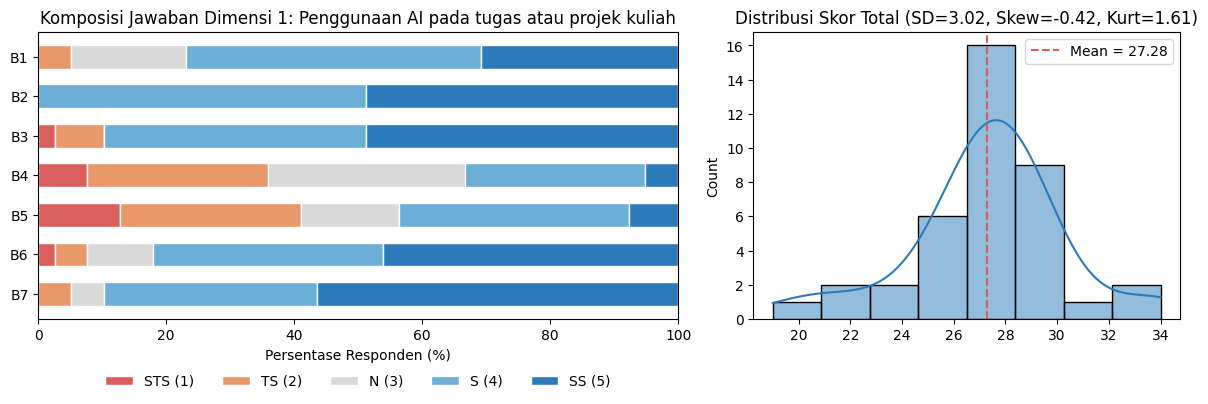

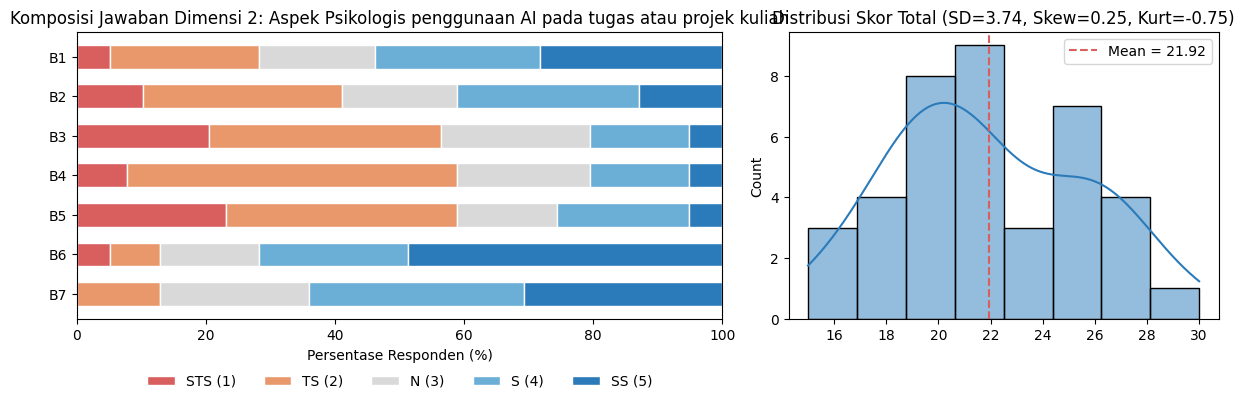

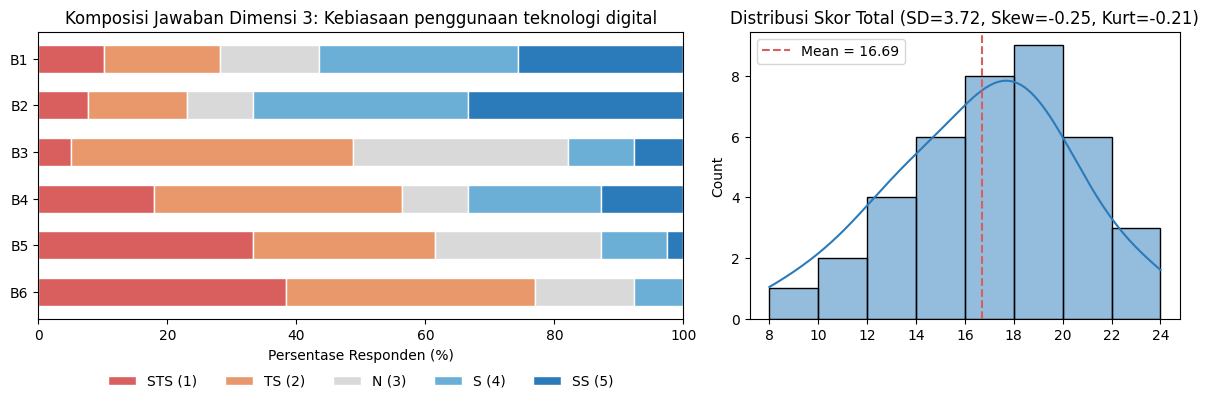

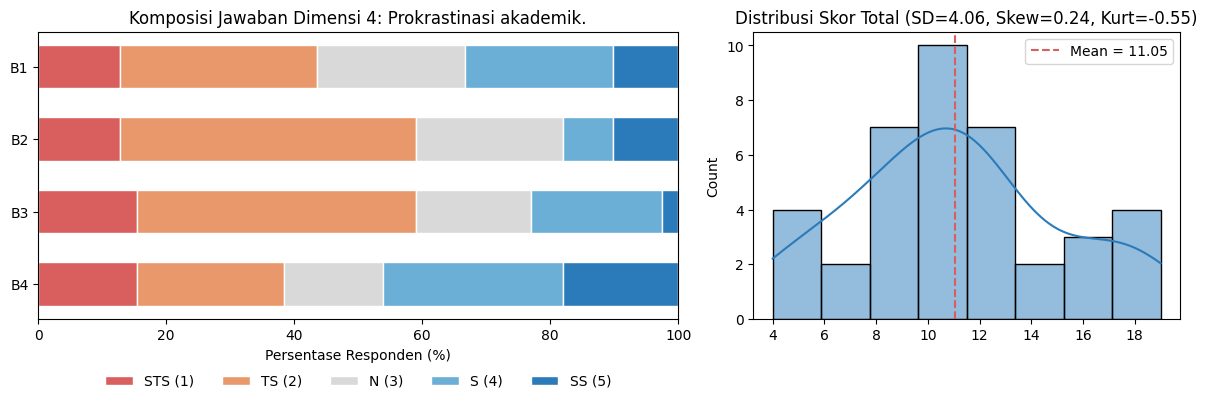

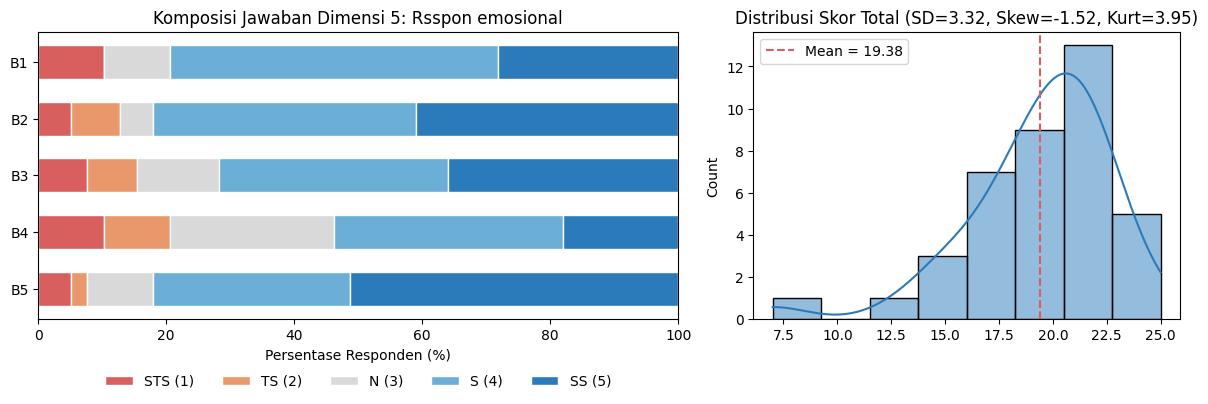

In [8]:
deskriptif_rows = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    skor_total = x.sum(axis=1)
    deskriptif_rows.append({
        "Dimensi / Butir": f"[TOTAL DIMENSI] {nama}",
        "Mean": round(skor_total.mean(), 3),
        "Median": round(skor_total.median(), 3),
        "Std Dev (SD)": round(skor_total.std(ddof=1), 3),
        "Skewness": round(skor_total.skew(), 3),
        "Kurtosis": round(skor_total.kurt(), 3),
    })
    for i, col in enumerate(daftar, 1):
        s = x[col]
        deskriptif_rows.append({
            "Dimensi / Butir": f"  {nama} - B{i}",
            "Mean": round(s.mean(), 3),
            "Median": round(s.median(), 3),
            "Std Dev (SD)": round(s.std(ddof=1), 3),
            "Skewness": round(s.skew(), 3),
            "Kurtosis": round(s.kurt(), 3),
        })

tabel_deskriptif = pd.DataFrame(deskriptif_rows)
display(tabel_deskriptif)

label_skala = ['STS (1)', 'TS (2)', 'N (3)', 'S (4)', 'SS (5)']
warna_skala = ['#d95f5f', '#e8986b', '#d9d9d9', '#6baed6', '#2b7bba']

for idx, (nama, daftar) in enumerate(dimensi.items(), 1):
    x = num[daftar]
    k_labels = [f'B{i}' for i in range(1, len(daftar)+1)]
    counts_df = pd.DataFrame(index=k_labels, columns=[1, 2, 3, 4, 5])
    for i, col in enumerate(daftar):
        counts_df.loc[k_labels[i]] = x[col].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0).values
    pct_df = counts_df.div(counts_df.sum(axis=1), axis=0) * 100

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.5, 1]})
    bottom = np.zeros(len(k_labels))
    for s_val, s_lbl, col_hex in zip([1, 2, 3, 4, 5], label_skala, warna_skala):
        vals = pct_df[s_val].values.astype(float)
        ax1.barh(k_labels, vals, left=bottom, label=s_lbl, color=col_hex, edgecolor='white', height=0.6)
        bottom += vals
    ax1.set_xlim(0, 100)
    ax1.invert_yaxis()
    ax1.set_xlabel('Persentase Responden (%)')
    ax1.set_title(f'Komposisi Jawaban Dimensi {idx}: {nama}')
    ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=5, frameon=False)

    skor_total = x.sum(axis=1)
    sns.histplot(skor_total, kde=True, ax=ax2, color='#2b7bba', bins=8)
    ax2.axvline(skor_total.mean(), color='#d95f5f', linestyle='--', label=f'Mean = {skor_total.mean():.2f}')
    ax2.set_title(f'Distribusi Skor Total (SD={skor_total.std(ddof=1):.2f}, Skew={skor_total.skew():.2f}, Kurt={skor_total.kurt():.2f})')
    ax2.legend()
    plt.tight_layout()
    plt.show()

In [9]:
hasil_perbaikan = []
for nama, daftar in dimensi.items():
    kolom_aktif = list(daftar)
    label_aktif = [f"B{i+1}" for i in range(len(daftar))]
    alpha_awal = cronbach_alpha(num[kolom_aktif])
    butir_dibuang = []
    while len(kolom_aktif) > 2:
        x_aktif = num[kolom_aktif]
        a_sekarang = cronbach_alpha(x_aktif)
        opsi_hapus = {i: cronbach_alpha(x_aktif.drop(columns=kolom_aktif[i])) for i in range(len(kolom_aktif))}
        idx_terbaik = max(opsi_hapus, key=opsi_hapus.get)
        if opsi_hapus[idx_terbaik] > a_sekarang:
            butir_dibuang.append(label_aktif.pop(idx_terbaik))
            kolom_aktif.pop(idx_terbaik)
        else:
            break
    alpha_akhir = cronbach_alpha(num[kolom_aktif])
    hasil_perbaikan.append({
        "Dimensi": nama,
        "Alpha Awal": round(alpha_awal, 3),
        "Butir Dibuang": ", ".join(butir_dibuang) if butir_dibuang else "-",
        "Butir Tersisa": ", ".join(label_aktif),
        "Alpha Setelah Perbaikan": round(alpha_akhir, 3),
        "Kategori Akhir": kategori(alpha_akhir)
    })

tabel_perbaikan = pd.DataFrame(hasil_perbaikan)
display(tabel_perbaikan)

gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")
with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    tabel_deskriptif.to_excel(w, sheet_name="Deskriptif", index=False)
    tabel_perbaikan.to_excel(w, sheet_name="Perbaikan_Instrumen", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

,Dimensi,Alpha Awal,Butir Dibuang,Butir Tersisa,Alpha Setelah Perbaikan,Kategori Akhir
0,Penggunaan AI pada tugas atau projek kuliah,0.370,"B7, B6, B2, B1, B3","B4, B5",0.634,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,0.375,"B6, B7, B1","B2, B3, B4, B5",0.688,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,0.478,"B5, B6","B1, B2, B3, B4",0.567,Tidak reliabel
3,Prokrastinasi akademik.,0.863,"B2, B4","B1, B3",0.907,Sangat baik
4,Rsspon emosional,0.489,"B3, B5, B4","B1, B2",0.679,Tidak reliabel


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>